# EN4554 – Assignment 2 on CNNs

**Name:** SULOJAN R.  
**Index No.:** 220626V

**GitHub:** [https://github.com/Sulojan2027/Vision_Coursework/tree/main/Sem07_Deep_Learning_for_Vision/Assignment_2](https://github.com/Sulojan2027/Vision_Coursework/tree/main/Sem07_Deep_Learning_for_Vision/Assignment_2)

---
**Claude / Copilot acknowledgement:** TODO (state which tools were used and for what; you must fully understand all code).

**Contents**
- [Setup](#setup)
- [Task 1: Backpropagation](#task-1-backpropagation)
- [Task 2: Optimizers](#task-2-optimizers)
- [Task 3: Regularization and residual connections](#task-3-regularization-and-residual-connections)
- [Task 4: CNN (Optional)](#task-4-cnn-optional)
- [Conclusion](#conclusion)

In [1]:
import time
import copy
import random
import math
import os
import json

from google.colab import drive
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import TensorDataset, DataLoader, random_split

In [2]:
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [3]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
set_seed(SEED)

In [4]:
drive.mount('/content/drive', force_remount=True)
DATA = '/content/drive/MyDrive/datasets/cifar10'
os.makedirs(DATA, exist_ok=True)
torchvision.datasets.CIFAR10(root=DATA, train=True, download=True)

Mounted at /content/drive


Dataset CIFAR10
    Number of datapoints: 50000
    Root location: /content/drive/MyDrive/datasets/cifar10
    Split: Train

### Data loading, split and normalization

In [5]:
def get_cifar10_splits(root=DATA, n_train=45_000, n_val=5_000, seed=SEED):
    full_train = torchvision.datasets.CIFAR10(root=root, train=True, download=False)
    test_set = torchvision.datasets.CIFAR10(root=root, train=False, download=False)
    g = torch.Generator().manual_seed(seed)
    train_set, val_set = random_split(full_train, [n_train, n_val], generator=g)
    return train_set, val_set, test_set

def compute_channel_stats(train_subset):
    data = train_subset.dataset.data[train_subset.indices] / 255.0
    return data.mean(axis=(0, 1, 2)), data.std(axis=(0, 1, 2))

train_data, val_data, test_data = get_cifar10_splits()
mean, std = compute_channel_stats(train_data)
print(f"Calculated per channel training statistics: Mean - {mean}, STD - {std}")

Calculated per channel training statistics: Mean - [0.49165571 0.48233405 0.44667923], STD - [0.24708116 0.24350869 0.26158066]


In [6]:
MEAN = torch.tensor(mean, dtype=torch.float32).view(1, 3, 1, 1)
STD  = torch.tensor(std,  dtype=torch.float32).view(1, 3, 1, 1)

def to_normalized_tensor(x_uint8):
    x = torch.from_numpy(x_uint8).float().div(255).permute(0, 3, 1, 2)
    return (x - MEAN) / STD

full = train_data.dataset
X_all, y_all = full.data, np.array(full.targets)

X_train = to_normalized_tensor(X_all[train_data.indices])
y_train = torch.from_numpy(y_all[train_data.indices])
X_val   = to_normalized_tensor(X_all[val_data.indices])
y_val   = torch.from_numpy(y_all[val_data.indices])
X_test  = to_normalized_tensor(test_data.data)
y_test  = torch.tensor(test_data.targets)

BATCH_SIZE = 128
train_loader = DataLoader(
    TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True,  pin_memory=True
)
val_loader = DataLoader(
    TensorDataset(X_val, y_val), batch_size=512, shuffle=False, pin_memory=True
)
test_loader = DataLoader(
    TensorDataset(X_test,  y_test), batch_size=512, shuffle=False, pin_memory=True
)
CLASSES = full.classes

### Common utilities (training / evaluation loops)

In [7]:
def evaluate(model, loader, criterion=None, device=DEVICE):
    """Return (mean_loss, accuracy) over a loader."""
    criterion = criterion or nn.CrossEntropyLoss()
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            logits = model(x)
            total_loss += criterion(logits, y).item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += y.size(0)
    return total_loss / n, correct / n

def train_one_epoch(model, loader, optimizer, criterion, augment_fn=None, batch_scheduler=None, device=DEVICE):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        y_true = y if y.ndim == 1 else y.argmax(1)
        if augment_fn is not None:
            x, y = augment_fn(x, y)             

        logits = model(x)
        loss = criterion(logits, y)                
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        if batch_scheduler is not None:
            batch_scheduler.step()

        total_loss += loss.item() * x.size(0)
        correct += (logits.argmax(1) == y_true).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, optimizer, epochs, criterion=None,
        scheduler=None, batch_scheduler=None, augment_fn=None, verbose=True, device=DEVICE):
    """Train for `epochs`; return history dict of per-epoch lists."""
    criterion = criterion or nn.CrossEntropyLoss()
    model.to(device)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "time": []}

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion,
                                          augment_fn, batch_scheduler)
        va_loss, va_acc = evaluate(model, val_loader, criterion)
        if scheduler is not None:         
            scheduler.step()
        dt = time.time() - t0

        for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc, dt)):
            history[k].append(v)
        if verbose:
            print(f"ep {epoch:3d} | train {tr_loss:.4f} / {tr_acc*100:5.2f}% "
                  f"| val {va_loss:.4f} / {va_acc*100:5.2f}% | {dt:.1f}s")
    return history


def count_parameters(model):
    """Number of trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def plot_history(histories: dict, keys=("train_loss", "val_acc"), title=None):
    """histories: {run_name: history_dict}. One subplot per key, one line per run."""
    fig, axes = plt.subplots(1, len(keys), figsize=(6 * len(keys), 4), squeeze=False)
    for ax, key in zip(axes[0], keys):
        for name, h in histories.items():
            y = np.array(h[key]) * (100 if "acc" in key else 1)
            ax.plot(range(1, len(y) + 1), y, label=name)
        ax.set_xlabel("epoch")
        ax.set_ylabel(key + (" (%)" if "acc" in key else ""))
        ax.set_title(key)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig

---
## Task 1: Backpropagation

### 1(a) Linear, ReLU and softmax cross-entropy with explicit forward / backward (no autograd)

Each layer has a `forward` (caches its input) and a `backward` (returns the gradient w.r.t. its input and stores parameter gradients). $G = \partial L/\partial y$ is the upstream gradient.

| layer | forward | backward |
|---|---|---|
| Linear | $y = xW + b$ | $\partial W = x^\top G,\ \ \partial b = \sum_i G_i,\ \ \partial x = G W^\top$ |
| ReLU | $y = \max(0, x)$ | $\partial x = G \odot \mathbb{1}[x > 0]$ |
| Sigmoid (1d) | $s = \sigma(x)$ | $\partial x = G \odot s(1-s)$ |
| Softmax + CE | $L = -\frac{1}{N}\sum_i \log p_{i,y_i}$ | $\partial z = \frac{1}{N}(p - Y)$, $Y$ = one-hot labels |

Weights use Kaiming initialization, $W \sim \mathcal{N}(0, 2/D_{in})$, $b = 0$.

In [8]:
class Linear:
    def __init__(self, in_features, out_features, device=DEVICE, dtype=torch.float32):
        self.W = torch.randn(in_features, out_features, device=device, dtype=dtype) * np.sqrt(2 / in_features)
        self.b = torch.zeros(out_features, device=device, dtype=dtype)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, grad_out):
        self.dW = self.x.T @ grad_out
        self.db = grad_out.sum(dim=0)
        return grad_out @ self.W.T
        
    def params(self):
        return [(self.W, self.dW), (self.b, self.db)]

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask
    def backward(self, grad_out):
        return grad_out * self.mask
    def params(self):
        return []
    
class Sigmoid:
    def forward(self, x):
        self.s = torch.sigmoid(x)
        return self.s
    def backward(self, grad_out):
        return grad_out * self.s * (1 - self.s)
    def params(self):
        return []
    
class SoftmaxCrossEntropy:
    def forward(self, logits, targets):
        N = logits.shape[0]
        z = logits - logits.max(dim=1, keepdim=True).values
        log_p = z - torch.logsumexp(z, dim=1, keepdim=True)
        self.p, self.y, self.N = log_p.exp(), targets, N
        return -log_p[torch.arange(N, device=logits.device), targets].mean()
    def backward(self):
        dlogits = self.p.clone()
        dlogits[torch.arange(self.N, device=dlogits.device), self.y] -= 1.0
        return dlogits / self.N

In [9]:
class MLP:
    def __init__(self, layer_sizes, activation=ReLU, device=DEVICE, dtype=torch.float32):
        self.layers = []
        for in_, out_ in zip(layer_sizes[:-1], layer_sizes[1:]):
            self.layers.append(Linear(in_, out_, device=device, dtype=dtype))
            self.layers.append(activation())
        self.layers.pop()
    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x
    def backward(self, grad):
        for rev_layer in reversed(self.layers):
            grad = rev_layer.backward(grad)
        return grad
    def params(self):
        return [pv for layer in self.layers for pv in layer.params()]
    def linear_layers(self):
        return [l for l in self.layers if isinstance(l, Linear)]

### 1(b) Gradient verification: autograd and centred finite differences

In [10]:
def autograd_reference(mlp, x, y):
    """Gradients via autograd"""
    leaves = []
    for k, l in enumerate(mlp.linear_layers()):
        W = l.W.detach().clone().requires_grad_()
        b = l.b.detach().clone().requires_grad_()
        leaves += [W, b]
        x = x @ W + b
        if k < len(mlp.linear_layers()) - 1:
            x = torch.relu(x)
    loss = F.cross_entropy(x, y)
    loss.backward()
    return [t.grad for t in leaves]

def finite_difference_grad(loss_fn, param, eps=1e-5, n_checks=50):
    flat = param.view(-1)
    idx = torch.randperm(flat.numel())[:n_checks]
    grads = torch.zeros(len(idx), dtype=flat.dtype)
    for k, i in enumerate(idx):
        w = flat[i].item()
        flat[i] = w + eps
        L_pos = loss_fn()
        flat[i] = w - eps
        L_neg = loss_fn()
        flat[i] = w
        grads[k] = (L_pos - L_neg) / (2 * eps)
    return grads, idx

def relative_error(a, b):
    return (a - b).norm() / max(a.norm() + b.norm(), 1e-12)

In [11]:
set_seed()
mlp64 = MLP([3072, 16, 10], dtype=torch.float64)
ce64 = SoftmaxCrossEntropy()
xb, yb = next(iter(train_loader))
x64 = xb[:8].view(8, -1).to(DEVICE, torch.float64)
y64 = yb[:8].to(DEVICE)

# manual gradients
ce64.forward(mlp64.forward(x64), y64)
mlp64.backward(ce64.backward())
manual = [g.clone() for _, g in mlp64.params()]

# autograd gradients
auto = autograd_reference(mlp64, x64, y64)

# finite differences (subset of entries per parameter)
loss_fn = lambda: ce64.forward(mlp64.forward(x64), y64).item()
names = ["W1", "b1", "W2", "b2"]
rows = []
for name, (p, _), g_man, g_auto in zip(names, mlp64.params(), manual, auto):
    g_fd, idx = finite_difference_grad(loss_fn, p, eps=1e-5, n_checks=50)
    g_man_sub = g_man.view(-1)[idx].cpu()
    rows.append({
        "param": name,
        "shape": tuple(p.shape),
        "rel_err (manual vs autograd)": relative_error(g_man, g_auto).item(),
        "allclose autograd": torch.allclose(g_man, g_auto, rtol=1e-6, atol=1e-8),
        "rel_err (manual vs FD)": relative_error(g_man_sub, g_fd).item(),
        "allclose FD": torch.allclose(g_man_sub, g_fd, rtol=1e-4, atol=1e-6),
    })

pd.set_option("display.float_format", "{:.2e}".format)
pd.DataFrame(rows)

,param,shape,rel_err (manual vs autograd),allclose autograd,rel_err (manual vs FD),allclose FD
0,W1,"(3072, 16)",0.00e+00,True,8.22e-11,True
1,b1,"(16,)",0.00e+00,True,7.48e-11,True
2,W2,"(16, 10)",0.00e+00,True,9.84e-11,True
3,b2,"(10,)",0.00e+00,True,4.98e-11,True


#### Interpretation of gradient check

- **Manual vs. autograd:** relative error **0** for all parameters, an exact match.
- **Manual vs. finite differences:** relative error **~5 × 10⁻¹¹ – 10⁻¹⁰**. Finite differences are only an approximation (truncation error ~ε² plus rounding), so a tiny error is expected.
- All `torch.allclose` checks are **True**, so the backward pass is correct. float64 is used so that rounding does not hide errors.

### 1(c) Train the MLP with SGD on flattened CIFAR-10

In [12]:
# Hyperparameters
LAYERS = [3072, 512, 256, 10]   # 2 hidden layers
LR, EPOCHS = 0.02, 15           # constant learning rate, batch size = BATCH_SIZE (128)

def evaluate_mlp(mlp, loader):
    """Forward-only evaluation of the manual MLP -> (mean_loss, accuracy)."""
    loss_ = SoftmaxCrossEntropy()
    total_loss, correct, n = 0.0, 0, 0
    for (x, y) in loader:
        x, y = (x.view(x.size(0), -1)).to(DEVICE), y.to(DEVICE)
        logits = mlp.forward(x)
        total_loss += loss_.forward(logits, y).item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        n += y.size(0)
    return total_loss / n, correct / n

set_seed()
mlp, ce = MLP(LAYERS), SoftmaxCrossEntropy()
hist = {"iter_loss": [], "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    total_loss, correct, n = 0.0, 0, 0          # reset accumulators every epoch
    for x, y in train_loader:
        x, y = (x.view(x.size(0), -1)).to(DEVICE), y.to(DEVICE)
        logits = mlp.forward(x)
        loss = ce.forward(logits, y)
        mlp.backward(ce.backward())
        for p, g in mlp.params():               # manual SGD step (in place)
            p -= LR * g
        hist["iter_loss"].append(loss.item())
        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        n += y.size(0)

    val_loss, val_acc = evaluate_mlp(mlp, val_loader)
    hist["train_loss"].append(total_loss / n)
    hist["train_acc"].append(correct / n)
    hist["val_loss"].append(val_loss)
    hist["val_acc"].append(val_acc)
    print(f"ep {epoch:2d} | train {total_loss/n:.4f} / {correct/n*100:5.2f}% "
          f"| val {val_loss:.4f} / {val_acc*100:5.2f}% | {time.time() - t0:.1f}s")

ep  1 | train 1.7432 / 39.24% | val 1.6020 / 43.82% | 1.1s
ep  2 | train 1.4706 / 48.64% | val 1.5399 / 46.28% | 1.1s
ep  3 | train 1.3523 / 53.03% | val 1.5088 / 46.92% | 1.1s
ep  4 | train 1.2647 / 56.36% | val 1.4861 / 47.92% | 1.1s
ep  5 | train 1.1879 / 59.38% | val 1.4674 / 49.54% | 1.1s
ep  6 | train 1.1223 / 61.64% | val 1.4391 / 50.00% | 1.1s
ep  7 | train 1.0591 / 64.02% | val 1.4341 / 50.56% | 1.2s
ep  8 | train 1.0052 / 66.15% | val 1.4393 / 51.00% | 1.1s
ep  9 | train 0.9486 / 68.03% | val 1.4494 / 51.08% | 1.1s
ep 10 | train 0.8943 / 70.29% | val 1.5137 / 49.66% | 1.1s
ep 11 | train 0.8461 / 71.91% | val 1.4838 / 51.94% | 1.1s
ep 12 | train 0.8004 / 73.50% | val 1.4742 / 51.88% | 1.1s
ep 13 | train 0.7470 / 75.27% | val 1.5415 / 50.34% | 1.1s
ep 14 | train 0.7029 / 77.14% | val 1.5723 / 51.08% | 1.1s
ep 15 | train 0.6607 / 78.72% | val 1.6649 / 49.54% | 1.1s


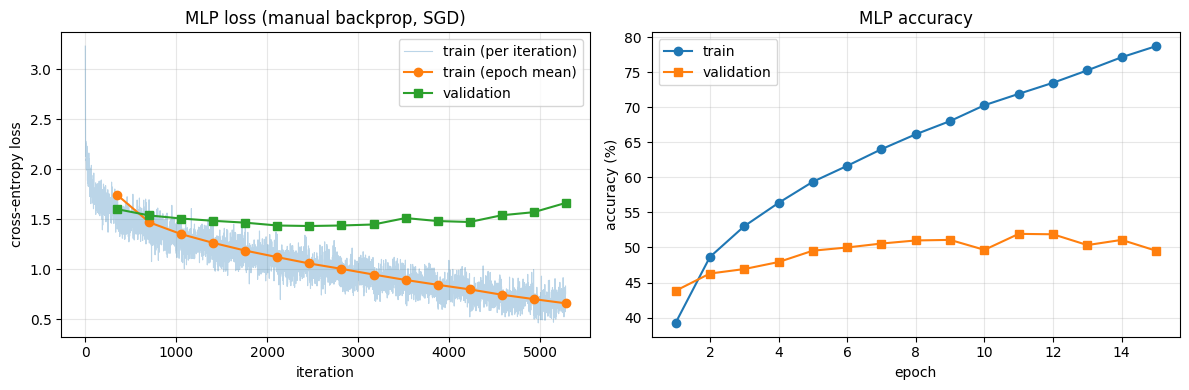

final val acc: 49.54%  |  best val acc: 51.94% (epoch 11)
final train acc: 78.72%  |  train-val gap: 29.18 pp


In [13]:
iters_per_epoch = len(train_loader)
epochs = np.arange(1, EPOCHS + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(hist["iter_loss"], alpha=0.3, lw=0.8, label="train (per iteration)")
ax1.plot(epochs * iters_per_epoch, hist["train_loss"], "o-", label="train (epoch mean)")
ax1.plot(epochs * iters_per_epoch, hist["val_loss"], "s-", label="validation")
ax1.set_xlabel("iteration"); ax1.set_ylabel("cross-entropy loss")
ax1.set_title("MLP loss (manual backprop, SGD)"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs, np.array(hist["train_acc"]) * 100, "o-", label="train")
ax2.plot(epochs, np.array(hist["val_acc"]) * 100, "s-", label="validation")
ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy (%)")
ax2.set_title("MLP accuracy"); ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

best_ep = int(np.argmax(hist["val_acc"]))
print(f"final val acc: {hist['val_acc'][-1]*100:.2f}%  |  best val acc: {hist['val_acc'][best_ep]*100:.2f}% (epoch {best_ep + 1})")
print(f"final train acc: {hist['train_acc'][-1]*100:.2f}%  |  train-val gap: {(hist['train_acc'][-1] - hist['val_acc'][-1])*100:.2f} pp")

#### Interpretation of MLP training

- **Converges:** train loss **1.74 → 0.66**, train accuracy **39% → 79%**, so the manual backprop works.
- **Overfits:** validation loss is lowest at **epoch 7 (1.43)** and then rises. Validation accuracy plateaus at **~50%** (best **51.9%**), giving a **~29 pp** train–validation gap.
- **Why overfits?:** flattening discards spatial structure, and with no weight sharing the ~**1.7 M** parameters memorize the training set instead of generalizing.
- **Hyperparameters:** a constant learning rate of 0.02 is stable but noisy. Early stopping (~epoch 7–11) or regularization would help more than extra epochs.

### 1(d) Per-layer gradient norm at initialization in a 10-layer MLP: sigmoid vs. ReLU

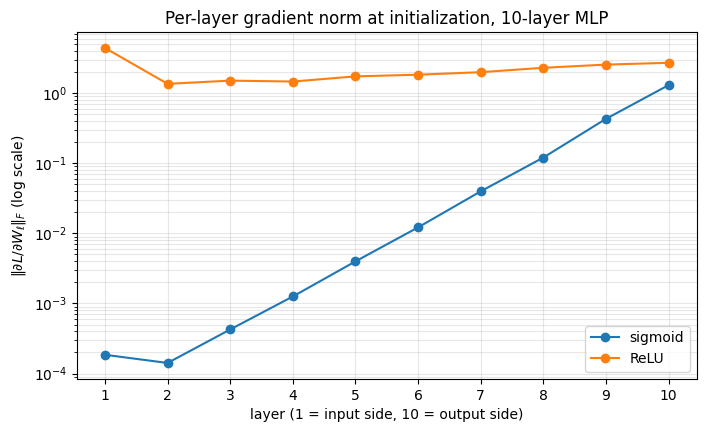

     sigmoid     ReLU
L1  1.85e-04 4.41e+00
L2  1.41e-04 1.36e+00
L3  4.25e-04 1.51e+00
L4  1.26e-03 1.46e+00
L5  3.98e-03 1.73e+00
L6  1.22e-02 1.83e+00
L7  3.97e-02 1.99e+00
L8  1.21e-01 2.30e+00
L9  4.30e-01 2.55e+00
L10 1.30e+00 2.71e+00
sigmoid  layer1 / layer10 = 1.42e-04
ReLU     layer1 / layer10 = 1.63e+00


In [14]:
sizes = [3072] + [256] * 9 + [10]          # 10 Linear layers, hidden width 256

set_seed()
xb, yb = next(iter(train_loader))          # one fixed batch (128 images), reproducible
x = xb.view(xb.size(0), -1).to(DEVICE)
y = yb.to(DEVICE)

def layer_grad_norms(activation):
    """Per-layer ||dL/dW|| at initialization (one forward/backward, no update)."""
    set_seed()                              # identical initial weights for both activations
    net, ce = MLP(sizes, activation=activation), SoftmaxCrossEntropy()
    ce.forward(net.forward(x), y)
    net.backward(ce.backward())
    return [l.dW.norm().item() for l in net.linear_layers()]

grad_norms = {
    "sigmoid": layer_grad_norms(Sigmoid),
    "ReLU":    layer_grad_norms(ReLU),
}

layers = np.arange(1, len(sizes))
plt.figure(figsize=(8, 4.5))
for name, norms in grad_norms.items():
    plt.plot(layers, norms, "o-", label=name)
plt.yscale("log")
plt.xticks(layers)
plt.xlabel("layer (1 = input side, 10 = output side)")
plt.ylabel(r"$\|\partial L / \partial W_\ell\|_F$ (log scale)")
plt.title("Per-layer gradient norm at initialization, 10-layer MLP")
plt.legend(); plt.grid(alpha=0.3, which="both")
plt.show()

print(pd.DataFrame(grad_norms, index=[f"L{i}" for i in layers]).to_string(float_format="{:.2e}".format))
for name, norms in grad_norms.items():
    print(f"{name:8s} layer1 / layer10 = {norms[0] / norms[-1]:.2e}")

#### Explanation: sigmoid vs. ReLU gradients

- **Sigmoid:** the gradient norm shrinks from **1.30** (layer 10) to **1.9 × 10⁻⁴** (layer 1), a ratio of **1.4 × 10⁻⁴** (~**3×** smaller per layer). Each layer multiplies the backward signal by $\sigma'(z) \le 0.25$, so it decays exponentially with depth: **vanishing gradients**, and the early layers barely learn.
- **ReLU:** the gradient norm stays between **1.4 and 4.4** in every layer (layer 1 / layer 10 = **1.63**). Its derivative is 1 for active units, and Kaiming initialization keeps the signal scale constant, so all layers get a useful gradient.

---
## Task 2: Optimizers

### 2(a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

We implement `MySGD` (with optional momentum) and `MyAdam` (with bias correction), then check that they give the same parameters as `torch.optim.SGD` and `torch.optim.Adam` when started from the same weights and trained on the same data.

In [15]:
class MySGD(torch.optim.Optimizer):
    """SGD with optional momentum (PyTorch convention: buffer starts at the first gradient)."""
    def __init__(self, params, lr=1e-2, momentum=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self, closure=None):
        for group in self.param_groups:
            lr, mu = group["lr"], group["momentum"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if mu != 0:
                    state = self.state[p]
                    if "buf" not in state:
                        state["buf"] = g.clone()                 # b_1 = g_1
                    else:
                        state["buf"] = mu * state["buf"] + g     # b_t = mu * b_{t-1} + g_t
                    g = state["buf"]
                p -= lr * g


class MyAdam(torch.optim.Optimizer):
    """Adam with bias correction."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self, closure=None):
        for group in self.param_groups:
            lr, eps = group["lr"], group["eps"]
            b1, b2 = group["betas"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                state = self.state[p]
                if not state:
                    state["t"], state["m"], state["v"] = 0, torch.zeros_like(p), torch.zeros_like(p)
                state["t"] += 1
                state["m"] = b1 * state["m"] + (1 - b1) * g          # 1st moment
                state["v"] = b2 * state["v"] + (1 - b2) * g * g      # 2nd moment
                m_hat = state["m"] / (1 - b1 ** state["t"])          # bias correction
                v_hat = state["v"] / (1 - b2 ** state["t"])
                p -= lr * m_hat / (v_hat.sqrt() + eps)

In [16]:
xb, yb = next(iter(train_loader))                 # one fixed batch, reused for every step
x_eq, y_eq = xb.to(DEVICE), yb.to(DEVICE)

def run(opt_cls, steps=50, **kw):
    set_seed()                                    # identical initial weights for both optimizers
    model = nn.Sequential(nn.Flatten(), nn.Linear(3072, 32), nn.ReLU(), nn.Linear(32, 10)).to(DEVICE)
    opt = opt_cls(model.parameters(), **kw)
    for _ in range(steps):
        opt.zero_grad()
        F.cross_entropy(model(x_eq), y_eq).backward()
        opt.step()
    return [p.detach() for p in model.parameters()]

pairs = {
    "SGD":            (MySGD,  torch.optim.SGD,  dict(lr=0.1)),
    "SGD + momentum": (MySGD,  torch.optim.SGD,  dict(lr=0.1, momentum=0.9)),
    "Adam":           (MyAdam, torch.optim.Adam, dict(lr=1e-3)),
}

rows = []
for name, (mine, ref, kw) in pairs.items():
    p_mine, p_ref = run(mine, **kw), run(ref, **kw)
    rows.append({
        "optimizer": name,
        "max |Δθ| after 50 steps": f"{max((a - b).abs().max().item() for a, b in zip(p_mine, p_ref)):.2e}",
        "torch.allclose": all(torch.allclose(a, b, rtol=1e-5, atol=1e-6) for a, b in zip(p_mine, p_ref)),
    })
pd.DataFrame(rows)

,optimizer,max |Δθ| after 50 steps,torch.allclose
0,SGD,5.96e-08,True
1,SGD + momentum,1.19e-07,True
2,Adam,2.98e-08,True


#### Interpretation of optimizer equivalence

- After 50 steps from the same weights, all three optimizers match PyTorch: max |Δθ| ≈ **10⁻⁸ – 10⁻⁷** and `torch.allclose` is **True**.
- The tiny differences are only **float32 rounding** (machine ε ≈ 1.2 × 10⁻⁷), caused by a slightly different order of operations, not by a different algorithm.

### 2(b) Optimizer trajectories on $f(x,y)=\tfrac12(x^2+50y^2)$

In [17]:
def f(xy):
    """f(x, y) = 0.5 (x^2 + 50 y^2); works for torch tensors and numpy grids."""
    return 0.5 * (xy[0] ** 2 + 50 * xy[1] ** 2)

START, STEPS = [-10.0, 1.0], 100

def trajectory(opt_cls, **kw):
    xy = torch.tensor(START, requires_grad=True)
    opt = opt_cls([xy], **kw)
    path = [xy.detach().clone()]
    for _ in range(STEPS):
        opt.zero_grad()
        f(xy).backward()
        opt.step()
        path.append(xy.detach().clone())
    return torch.stack(path).numpy()

TRAJ_CFG = {
    "SGD (lr=0.035)":                 (MySGD,  dict(lr=0.035)),                 # stable only for lr < 2/50 = 0.04
    "SGD + momentum (lr=0.035, 0.9)": (MySGD,  dict(lr=0.035, momentum=0.9)),   # same lr as SGD
    "Adam (lr=0.5)":                  (MyAdam, dict(lr=0.5)),
}
trajectories = {name: trajectory(cls, **kw) for name, (cls, kw) in TRAJ_CFG.items()}

for name, path in trajectories.items():
    fv = np.array([f(p) for p in path])
    hit = np.argmax(fv < 1e-2) if (fv < 1e-2).any() else None
    print(f"{name:32s} final (x, y) = ({path[-1, 0]:+.4f}, {path[-1, 1]:+.4f}) | f = {fv[-1]:.2e} | steps to f < 1e-2: {hit}")

SGD (lr=0.035)                   final (x, y) = (-0.2836, +0.0000) | f = 4.02e-02 | steps to f < 1e-2: None
SGD + momentum (lr=0.035, 0.9)   final (x, y) = (-0.0451, +0.0042) | f = 1.45e-03 | steps to f < 1e-2: 76
Adam (lr=0.5)                    final (x, y) = (+0.0421, -0.0043) | f = 1.36e-03 | steps to f < 1e-2: 54


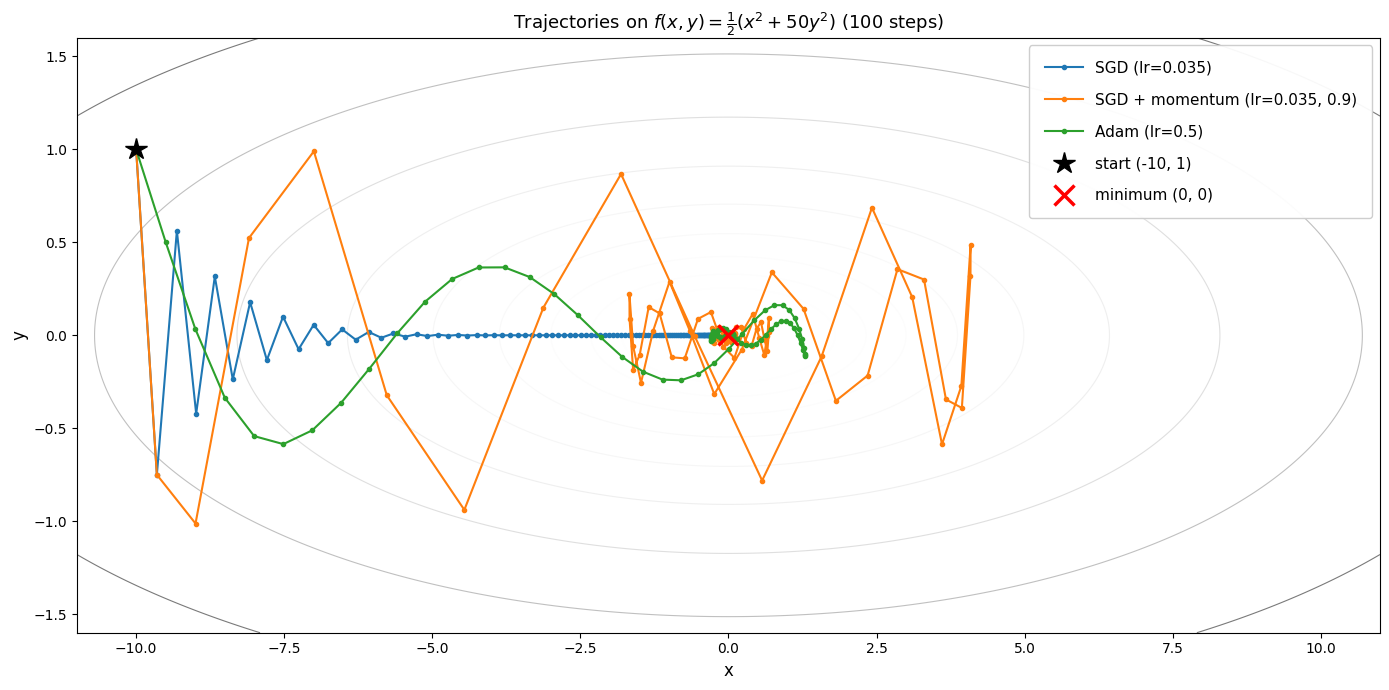

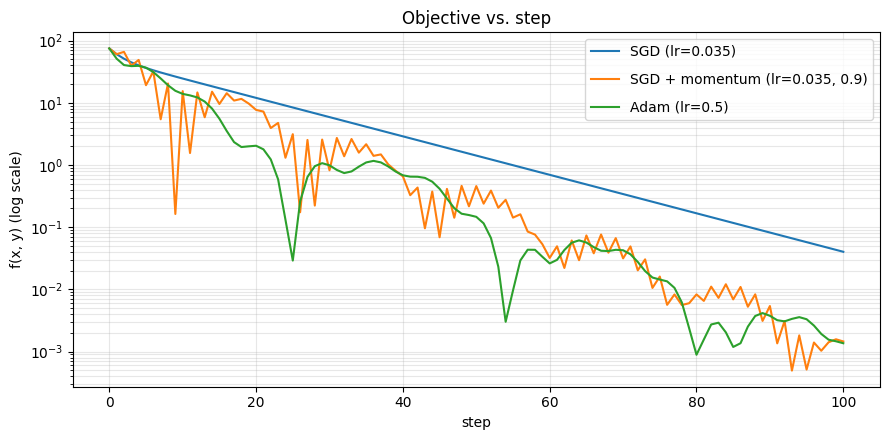

In [18]:
xs, ys = np.linspace(-11, 11, 400), np.linspace(-1.6, 1.6, 400)
X, Y = np.meshgrid(xs, ys)
Z = f(np.stack([X, Y]))

# 1) trajectories on the contour plot
plt.figure(figsize=(14, 7))
plt.contour(X, Y, Z, levels=np.logspace(-2, 2.2, 20), cmap="Greys", linewidths=0.8)
for name, path in trajectories.items():
    plt.plot(path[:, 0], path[:, 1], "o-", ms=3, lw=1.5, label=name)
plt.plot(*START, "k*", ms=16, label="start (-10, 1)")
plt.plot(0, 0, "rx", ms=14, mew=2.5, label="minimum (0, 0)")
plt.xlabel("x", fontsize=12); plt.ylabel("y", fontsize=12)
plt.title(r"Trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$" + f" ({STEPS} steps)", fontsize=13)
plt.legend(loc="upper right", fontsize=11, labelspacing=1.1, borderpad=1.0, handlelength=2.5, framealpha=0.95)
plt.tight_layout(); plt.show()

# 2) objective value vs. step
plt.figure(figsize=(9, 4.5))
for name, path in trajectories.items():
    plt.plot([f(p) for p in path], lw=1.5, label=name)
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("f(x, y) (log scale)")
plt.title("Objective vs. step"); plt.grid(alpha=0.3, which="both")
plt.legend(labelspacing=1.0)
plt.tight_layout(); plt.show()

#### Explanation of trajectory differences

$f$ is **50× steeper in $y$ than in $x$**, which makes a long, narrow valley.

- **SGD (lr = 0.035):** the lr must stay below 2/50 = 0.04 for the steep $y$ direction, so the steps along the flat $x$ direction are tiny. It **zig-zags in $y$** and crawls in $x$: after 100 steps $f$ = **4 × 10⁻²** (never below 10⁻²).
- **SGD + momentum (lr = 0.035, μ = 0.9):** velocity builds up along $x$ while the $y$ zig-zags cancel out, so it reaches $f$ < 10⁻² in **76 steps**. It overshoots a little around the minimum.
- **Adam (lr = 0.5):** it scales each coordinate's step separately, so $x$ and $y$ move at a similar rate. The path is **almost straight** and reaches $f$ < 10⁻² fastest, in **54 steps**.

### 2(c) Small CNN with each optimizer at three learning rates

- **Model:** `SmallCNN`, 3 × [Conv3×3 → ReLU → MaxPool] (32/64/128) → FC 256 → FC 10, **620k** parameters, no batch norm.
- **Setup:** 10 epochs, batch 128, same seed for every run.
- **Learning rates:** SGD {0.003, 0.03, 0.3}, SGD + momentum {0.0003, 0.003, 0.03}, Adam {1e-4, 1e-3, 1e-2}. The momentum grid is 10× smaller because momentum 0.9 makes the effective step ~10× larger.

In [19]:
class SmallCNN(nn.Module):
    """3 x [Conv3x3 -> ReLU -> MaxPool2] (32/64/128) -> FC 256 -> FC 10. No batch norm."""
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 32x32 -> 16x16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 16x16 -> 8x8
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 8x8 -> 4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print(f"SmallCNN parameters: {count_parameters(SmallCNN()):,}")

SmallCNN parameters: 620,362


In [20]:
EPOCHS_OPT = 10
GRID = {
    "SGD":            (MySGD,  dict(momentum=0.0), [3e-3, 3e-2, 3e-1]),
    "SGD + momentum": (MySGD,  dict(momentum=0.9), [3e-4, 3e-3, 3e-2]),
    "Adam":           (MyAdam, dict(),             [1e-4, 1e-3, 1e-2]),
}

opt_hist = {}
for name, (cls, kw, lrs) in GRID.items():
    for lr in lrs:
        set_seed()                                   # same init + batch order for every run
        model = SmallCNN().to(DEVICE)
        opt = cls(model.parameters(), lr=lr, **kw)
        t0 = time.time()
        opt_hist[(name, lr)] = fit(model, train_loader, val_loader, opt, EPOCHS_OPT, verbose=False)
        h = opt_hist[(name, lr)]
        print(f"{name:15s} lr={lr:<7g} | final train loss {h['train_loss'][-1]:.4f} "
              f"| best val acc {max(h['val_acc'])*100:5.2f}% | {time.time() - t0:.0f}s")

SGD             lr=0.003   | final train loss 1.6809 | best val acc 39.56% | 26s
SGD             lr=0.03    | final train loss 0.8132 | best val acc 66.66% | 26s
SGD             lr=0.3     | final train loss 0.2226 | best val acc 71.84% | 26s
SGD + momentum  lr=0.0003  | final train loss 1.6832 | best val acc 40.56% | 26s
SGD + momentum  lr=0.003   | final train loss 0.7655 | best val acc 70.18% | 26s
SGD + momentum  lr=0.03    | final train loss 0.2111 | best val acc 75.42% | 26s
Adam            lr=0.0001  | final train loss 0.9921 | best val acc 63.24% | 27s
Adam            lr=0.001   | final train loss 0.1907 | best val acc 75.98% | 27s
Adam            lr=0.01    | final train loss 2.3034 | best val acc 10.24% | 27s


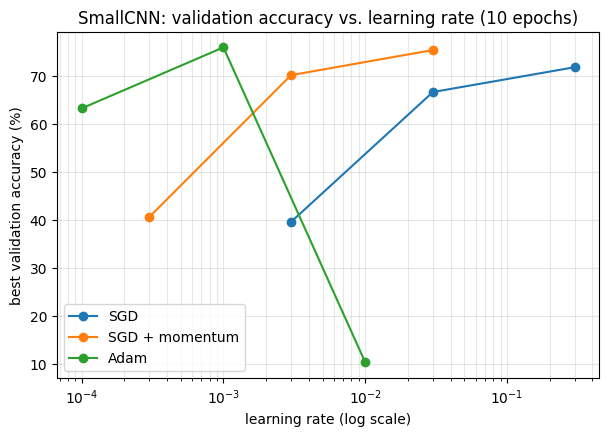

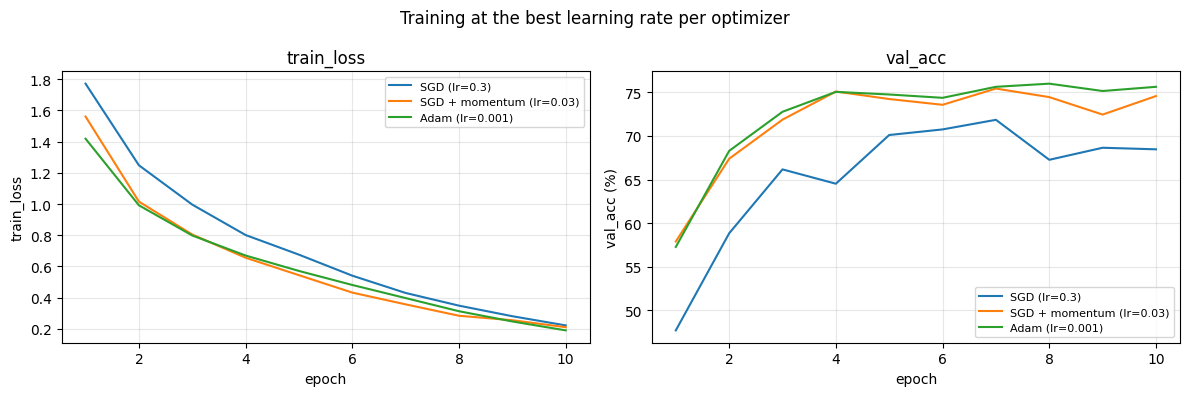

,optimizer,lr,best val acc (%),final val acc (%),final train loss,best lr
0,SGD,0.003,3.96e+01,3.96e+01,1.68e+00,
1,SGD,0.03,6.67e+01,6.67e+01,8.13e-01,
2,SGD,0.3,7.18e+01,6.85e+01,2.23e-01,✓
3,SGD + momentum,0.0003,4.06e+01,4.06e+01,1.68e+00,
4,SGD + momentum,0.003,7.02e+01,7.02e+01,7.65e-01,
5,SGD + momentum,0.03,7.54e+01,7.46e+01,2.11e-01,✓
6,Adam,0.0001,6.32e+01,6.31e+01,9.92e-01,
7,Adam,0.001,7.60e+01,7.56e+01,1.91e-01,✓
8,Adam,0.01,1.02e+01,9.42e+00,2.30e+00,


In [21]:
best_lr = {}
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, (_, _, lrs) in GRID.items():
    best_val = [max(opt_hist[(name, lr)]["val_acc"]) * 100 for lr in lrs]
    best_lr[name] = lrs[int(np.argmax(best_val))]
    ax.plot(lrs, best_val, "o-", label=name)
ax.set_xscale("log")
ax.set_xlabel("learning rate (log scale)"); ax.set_ylabel("best validation accuracy (%)")
ax.set_title(f"SmallCNN: validation accuracy vs. learning rate ({EPOCHS_OPT} epochs)")
ax.grid(alpha=0.3, which="both"); ax.legend()
plt.show()

plot_history({f"{name} (lr={best_lr[name]:g})": opt_hist[(name, best_lr[name])] for name in GRID},
             keys=("train_loss", "val_acc"), title="Training at the best learning rate per optimizer")

rows = []
for name, (_, _, lrs) in GRID.items():
    for lr in lrs:
        h = opt_hist[(name, lr)]
        rows.append({
            "optimizer": name,
            "lr": f"{lr:g}",
            "best val acc (%)": round(max(h["val_acc"]) * 100, 2),
            "final val acc (%)": round(h["val_acc"][-1] * 100, 2),
            "final train loss": round(h["train_loss"][-1], 4),
            "best lr": "✓" if lr == best_lr[name] else "",
        })
pd.DataFrame(rows)


#### Discussion of optimizer sensitivity

| optimizer | best val acc at the 3 lrs (low → high) | best lr |
|---|---|---|
| SGD | 39.6 / 66.7 / **71.8** % | 0.3 |
| SGD + momentum | 40.6 / 70.2 / **75.4** % | 0.03 |
| Adam | 63.2 / **76.0** / 10.2 % | 0.001 |

- **Adam is best (76.0%)** and reaches the lowest training loss (**0.19**, vs. 0.21 for momentum and 0.22 for SGD).
- **Adam is the most sensitive to a high lr:** at lr = 0.01 it **diverged** (loss stuck at 2.30 = ln 10, chance-level accuracy). At a low lr it is the most robust (63% vs. ~40%).
- **SGD and momentum fail gracefully:** a low lr just makes them slow. Each momentum run beats the SGD run with a 10× larger lr (40.6 vs. 39.6, 70.2 vs. 66.7, 75.4 vs. 71.8%).
- **Caveat:** only 3 lrs, 10 epochs and 1 seed.

---
## Task 3: Regularization and residual connections

### 3(a) Regularization study on 5k training images

- **Model:** `SmallBNCNN` (the 2(c) CNN with batch norm), trained on a fixed **5k** subset and validated on the 5k validation split.
- **Setup:** 30 epochs, SGD (lr 0.05, momentum 0.9) with a cosine schedule, same seed for all runs.
- **Configurations:** baseline · weight decay (5e-4) · dropout (0.5) · flip+crop · cutout (8×8) · mixup (α = 0.4) · all combined.

In [22]:
def conv_bn(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU())

class SmallBNCNN(nn.Module):
    """3 x [Conv3x3 -> BN -> ReLU -> MaxPool2] (32/64/128) -> FC 256 -> FC 10, with optional dropout."""
    def __init__(self, p_drop=0.0, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            conv_bn(3, 32), nn.MaxPool2d(2),       # 32x32 -> 16x16
            conv_bn(32, 64), nn.MaxPool2d(2),      # 16x16 -> 8x8
            conv_bn(64, 128), nn.MaxPool2d(2),     # 8x8 -> 4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(p_drop),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print(f"SmallBNCNN parameters: {count_parameters(SmallBNCNN()):,}")

SmallBNCNN parameters: 620,586


**Augmentations (implemented from scratch, applied batch-wise on the GPU):**

In [23]:
# All augmentations: (x, y) -> (x, y) on a normalized GPU batch x of shape (N, 3, 32, 32).

def random_flip_crop(x, y, pad=4):
    """Random horizontal flip + random 32x32 crop from the zero-padded image."""
    N, _, H, W = x.shape
    flip = torch.rand(N, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))
    i = torch.randint(0, 2 * pad + 1, (N,)).tolist()
    j = torch.randint(0, 2 * pad + 1, (N,)).tolist()
    x = torch.stack([xp[k, :, i[k]:i[k] + H, j[k]:j[k] + W] for k in range(N)])
    return x, y

def cutout(x, y, size=8):
    """Zero out one random size x size square per image (it may be clipped at the border)."""
    N, _, H, W = x.shape
    cy = torch.randint(0, H, (N, 1, 1), device=x.device)
    cx = torch.randint(0, W, (N, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device).view(1, H, 1)
    xs = torch.arange(W, device=x.device).view(1, 1, W)
    mask = ((ys - cy).abs() < size // 2) & ((xs - cx).abs() < size // 2)    # (N, H, W)
    return x * (~mask).unsqueeze(1), y

def mixup(x, y, alpha=0.4, num_classes=10):
    """Mix pairs of images and their one-hot labels with lam ~ Beta(alpha, alpha)."""
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(x.size(0), device=x.device)
    y1h = F.one_hot(y, num_classes).float()
    return lam * x + (1 - lam) * x[perm], lam * y1h + (1 - lam) * y1h[perm]

def compose(*fns):
    """Chain augmentations, e.g. compose(random_flip_crop, cutout)."""
    def inner(x, y):
        for fn in fns:
            x, y = fn(x, y)
        return x, y
    return inner

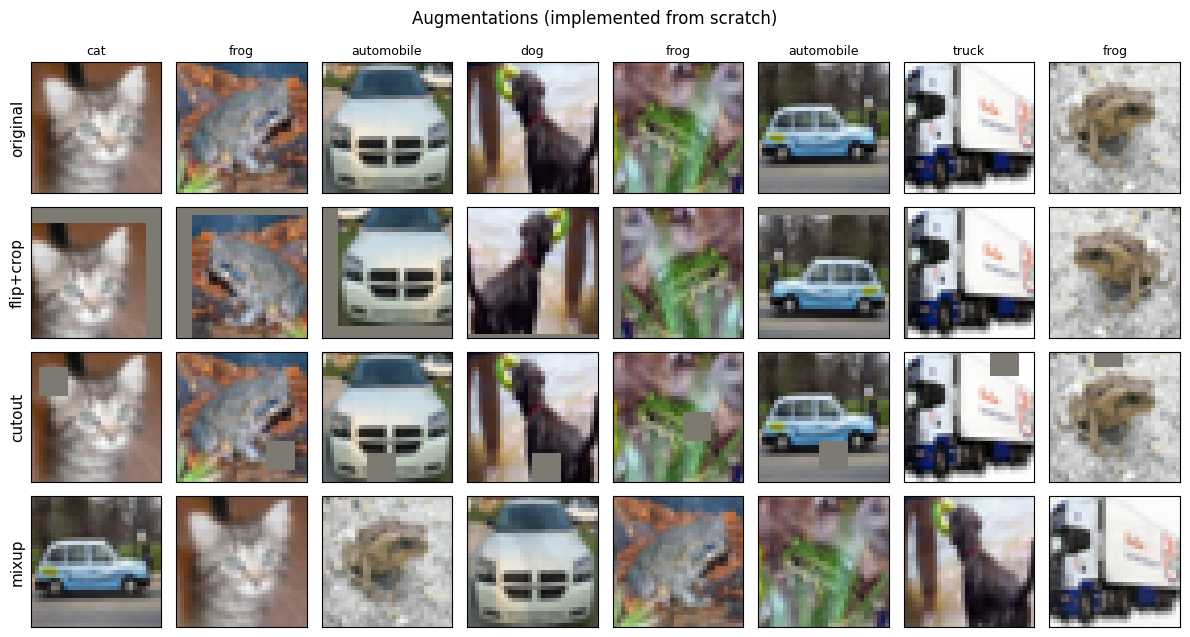

In [24]:
set_seed()
xb, yb = next(iter(train_loader))
xb, yb = xb[:8].to(DEVICE), yb[:8].to(DEVICE)

aug_rows = {
    "original":  xb,
    "flip+crop": random_flip_crop(xb, yb)[0],
    "cutout":    cutout(xb, yb)[0],
    "mixup":     mixup(xb, yb)[0],
}
mean_d, std_d = MEAN.to(DEVICE), STD.to(DEVICE)

fig, axes = plt.subplots(len(aug_rows), 8, figsize=(12, 6.5))
for r, (name, imgs) in enumerate(aug_rows.items()):
    imgs = (imgs * std_d + mean_d).clamp(0, 1).cpu()
    for c in range(8):
        axes[r, c].imshow(imgs[c].permute(1, 2, 0))
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(name, fontsize=11)
for c in range(8):
    axes[0, c].set_title(CLASSES[yb[c]], fontsize=9)
plt.suptitle("Augmentations (implemented from scratch)")
plt.tight_layout(); plt.show()

In [25]:
# Results are saved to Drive after every run, so a Colab disconnect does not lose finished runs.
RESULTS_DIR = "/content/drive/MyDrive/a2_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

def run_cached(tag, train_fn):
    """Load the history for `tag` from Drive if it exists, otherwise run train_fn() and save it."""
    path = os.path.join(RESULTS_DIR, f"{tag}.json")
    if os.path.exists(path):
        print(f"[loaded] {tag}")
        with open(path) as fh:
            return json.load(fh)
    h = train_fn()
    with open(path, "w") as fh:
        json.dump(h, fh)
    return h

# fixed 5k training subset (same for every configuration)
g = torch.Generator().manual_seed(SEED)
idx5k = torch.randperm(len(X_train), generator=g)[:5000]
small_loader = DataLoader(TensorDataset(X_train[idx5k], y_train[idx5k]), batch_size=128, shuffle=True, pin_memory=True)
small_eval_loader = DataLoader(TensorDataset(X_train[idx5k], y_train[idx5k]), batch_size=512, shuffle=False)

EPOCHS_REG, LR_REG, WD, P_DROP = 30, 0.05, 5e-4, 0.5
CONFIGS = {   # name: (dropout p, weight decay, augmentation)
    "baseline":     (0.0,    0.0, None),
    "weight decay": (0.0,    WD,  None),
    "dropout":      (P_DROP, 0.0, None),
    "flip+crop":    (0.0,    0.0, random_flip_crop),
    "cutout":       (0.0,    0.0, cutout),
    "mixup":        (0.0,    0.0, mixup),
    "all combined": (P_DROP, WD,  compose(random_flip_crop, cutout, mixup)),
}

def train_reg(p_drop, wd, aug):
    set_seed()
    model = SmallBNCNN(p_drop=p_drop).to(DEVICE)
    opt = torch.optim.SGD(model.parameters(), lr=LR_REG, momentum=0.9, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS_REG)
    h = fit(model, small_loader, val_loader, opt, EPOCHS_REG, scheduler=sched, augment_fn=aug, verbose=False)
    h["clean_train_acc"] = evaluate(model, small_eval_loader)[1]     # train acc on un-augmented images
    return h

reg_hist = {}
for name, (p, wd, aug) in CONFIGS.items():
    t0 = time.time()
    reg_hist[name] = run_cached(f"3a_{name.replace(' ', '_').replace('+', '_')}", lambda: train_reg(p, wd, aug))
    h = reg_hist[name]
    print(f"{name:13s} | train acc {h['clean_train_acc']*100:5.1f}% | val acc {h['val_acc'][-1]*100:5.1f}% | {time.time() - t0:.0f}s")

baseline      | train acc  99.9% | val acc  64.2% | 12s
weight decay  | train acc  99.9% | val acc  64.4% | 12s
dropout       | train acc  68.9% | val acc  59.0% | 12s
flip+crop     | train acc  79.8% | val acc  69.6% | 14s
cutout        | train acc  99.7% | val acc  65.8% | 13s
mixup         | train acc  98.2% | val acc  65.7% | 13s
all combined  | train acc  48.7% | val acc  47.5% | 15s


,config,train acc (%),val acc (%),gap (pp)
0,baseline,9.99e+01,6.42e+01,3.57e+01
1,weight decay,9.99e+01,6.44e+01,3.55e+01
2,dropout,6.89e+01,5.90e+01,9.86e+00
3,flip+crop,7.98e+01,6.96e+01,1.02e+01
4,cutout,9.97e+01,6.58e+01,3.39e+01
5,mixup,9.82e+01,6.57e+01,3.25e+01
6,all combined,4.87e+01,4.75e+01,1.18e+00


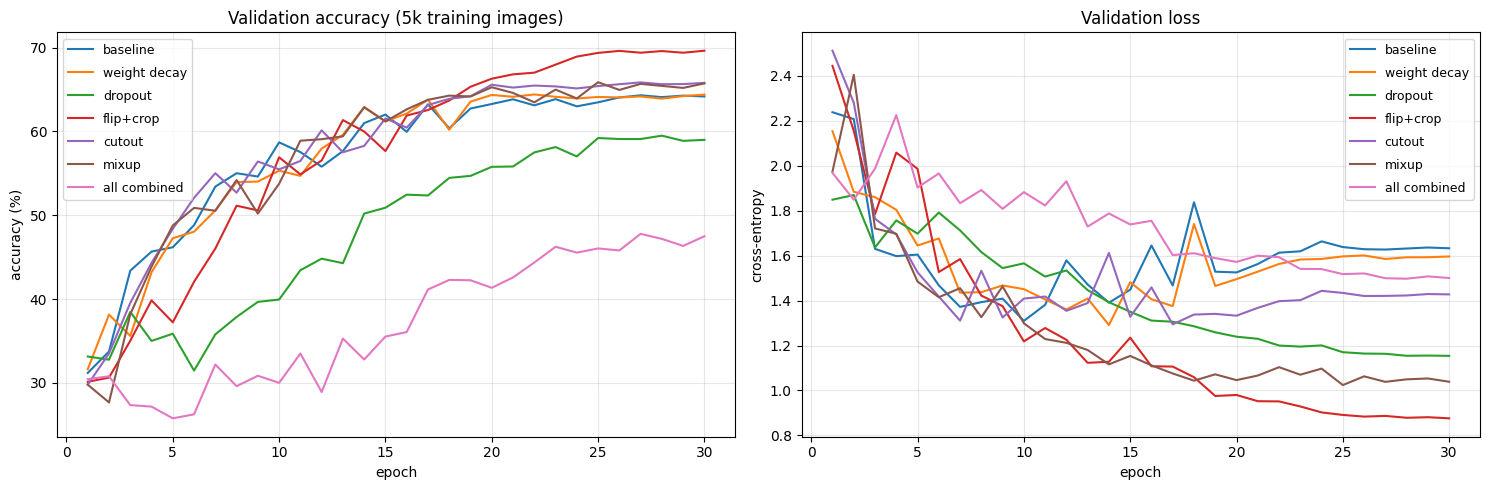

In [26]:
# Final-epoch numbers; train acc is measured on the clean (un-augmented) 5k training images.
rows = []
for name, h in reg_hist.items():
    tr, va = h["clean_train_acc"] * 100, h["val_acc"][-1] * 100
    rows.append({"config": name, "train acc (%)": round(tr, 2), "val acc (%)": round(va, 2), "gap (pp)": round(tr - va, 2)})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, h in reg_hist.items():
    ep = range(1, len(h["val_acc"]) + 1)
    line, = axes[0].plot(ep, np.array(h["val_acc"]) * 100, label=name)
    axes[1].plot(ep, h["val_loss"], color=line.get_color(), label=name)
axes[0].set_title("Validation accuracy (5k training images)"); axes[0].set_ylabel("accuracy (%)")
axes[1].set_title("Validation loss"); axes[1].set_ylabel("cross-entropy")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=9, labelspacing=0.8)
plt.tight_layout(); plt.show()

#### Interpretation of regularization results

Train accuracy is measured on the clean (un-augmented) 5k images at the final epoch.

- **Baseline overfits:** **99.9%** train vs. **64.2%** val, a **36 pp** gap.
- **Flip+crop works best:** val **69.6%** (+5.4 pp), gap down to **10 pp**, and the lowest val loss (0.88). It adds realistic variation, so the model cannot just memorize 5k images.
- **Cutout and mixup** help a little (val **65.8%** / **65.7%**), but the gap stays large (~33 pp).
- **Weight decay** has almost no effect (64.4%). With batch norm, the conv weights' scale does not matter much, and 30 epochs is short.
- **Dropout (0.5)** shrinks the gap (10 pp) but **lowers** val accuracy (59.0%): it is too strong for this small model, which then underfits.
- **All combined** removes the gap (**1 pp**) but **underfits badly** (47.5% val, still rising at epoch 30). The methods **do not add up**: stacking them is too much regularization for 5k images and 30 epochs.
- **Caveat:** one seed and untuned strengths; each method would need its own tuning.

### 3(b) Plain vs. residual CIFAR-style networks, depth $6n+2$ ∈ {8, 20, 56}

- Three stages (16/32/64 channels), global average pooling, batch norm, Kaiming initialization.
- **The only difference is the shortcut:** identity, plus a stride-2 subsample with zero-padded channels when the shape changes (no extra parameters, so plain and residual nets have identical parameter counts).
- **Setup:** 15 epochs, SGD (lr 0.1, momentum 0.9, weight decay 1e-4) with a cosine schedule, no augmentation, same seed for all 6 models.

In [27]:
class BasicBlock(nn.Module):
    """conv-BN-ReLU-conv-BN (+ shortcut) -> ReLU.
    Shortcut (residual only): identity; when the shape changes, subsample by 2 and zero-pad the
    new channels (option A of He et al.) - no extra parameters, so plain and residual nets are identical
    except for the addition."""
    def __init__(self, in_ch, out_ch, stride, residual: bool):
        super().__init__()
        self.residual = residual
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.stride, self.pad_ch = stride, out_ch - in_ch

    def shortcut(self, x):
        if self.stride != 1:
            x = x[:, :, ::self.stride, ::self.stride]
        if self.pad_ch > 0:
            x = F.pad(x, (0, 0, 0, 0, 0, self.pad_ch))     # zero-pad the channel dimension
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class CifarNet(nn.Module):
    """Depth 6n + 2: stem conv + 3 stages x n blocks x 2 convs (16/32/64 channels) + FC."""
    def __init__(self, n, residual: bool, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU())
        blocks, in_ch = [], 16
        for out_ch, stride in [(16, 1), (32, 2), (64, 2)]:              # 32x32 -> 16x16 -> 8x8
            for k in range(n):
                blocks.append(BasicBlock(in_ch, out_ch, stride if k == 0 else 1, residual))
                in_ch = out_ch
        self.blocks = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, num_classes))

        for m in self.modules():                                       # Kaiming initialization
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.blocks(self.stem(x)))

In [28]:
rows = []
for n in (1, 3, 9):
    for residual in (False, True):
        m = CifarNet(n, residual)
        n_layers = sum(isinstance(l, (nn.Conv2d, nn.Linear)) for l in m.modules())
        assert n_layers == 6 * n + 2
        rows.append({"depth": 6 * n + 2, "family": "residual" if residual else "plain",
                     "weight layers": n_layers, "parameters": f"{count_parameters(m):,}"})
pd.DataFrame(rows)

,depth,family,weight layers,parameters
0,8,plain,8,"75,290"
1,8,residual,8,"75,290"
2,20,plain,20,"269,722"
3,20,residual,20,"269,722"
4,56,plain,56,"853,018"
5,56,residual,56,"853,018"


In [29]:
EPOCHS_RES = 15     # same setup for all 6 models; no augmentation (we compare optimization, not regularization)

def train_res(n, residual):
    set_seed()
    model = CifarNet(n, residual).to(DEVICE)
    opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS_RES)
    return fit(model, train_loader, val_loader, opt, EPOCHS_RES, scheduler=sched, verbose=False)

res_hist = {}
for n in (1, 3, 9):
    for residual in (False, True):
        name = f"{'residual' if residual else 'plain'}-{6 * n + 2}"
        t0 = time.time()
        res_hist[name] = run_cached(f"3b_{name}", lambda: train_res(n, residual))
        h = res_hist[name]
        print(f"{name:12s} | final train loss {h['train_loss'][-1]:.4f} | final val acc {h['val_acc'][-1]*100:5.2f}% | {time.time() - t0:.0f}s")

plain-8      | final train loss 0.2421 | final val acc 79.90% | 78s
residual-8   | final train loss 0.2781 | final val acc 78.86% | 82s
plain-20     | final train loss 0.1048 | final val acc 80.80% | 189s
residual-20  | final train loss 0.0776 | final val acc 77.34% | 197s
plain-56     | final train loss 1.5559 | final val acc 41.60% | 524s
residual-56  | final train loss 0.1256 | final val acc 76.80% | 545s


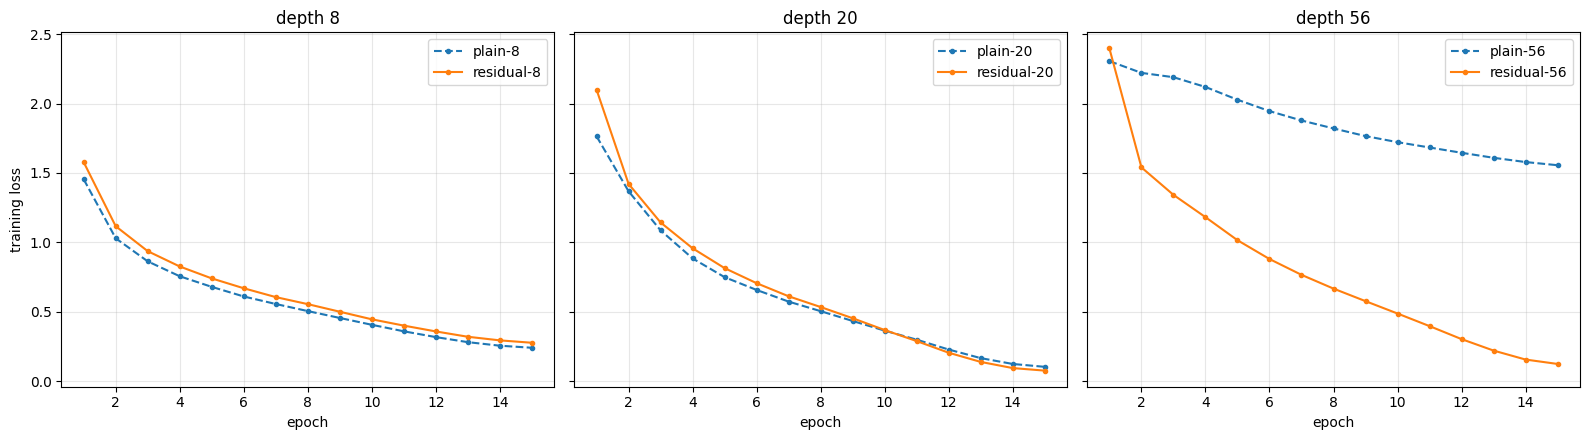

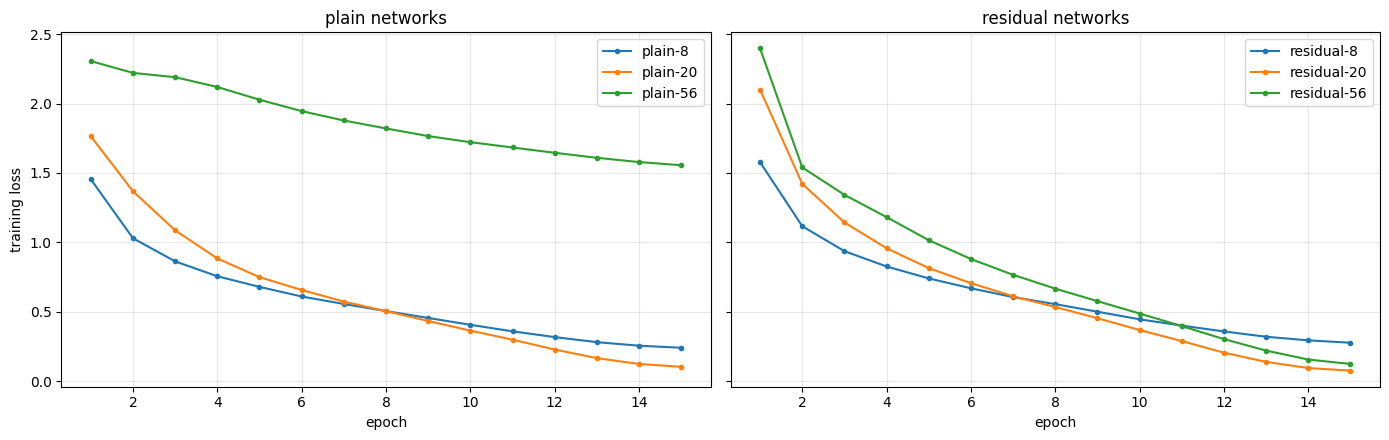

,model,final train loss,final train acc (%),final val acc (%)
0,plain-8,2.42e-01,9.27e+01,7.99e+01
1,residual-8,2.78e-01,9.14e+01,7.89e+01
2,plain-20,1.05e-01,9.72e+01,8.08e+01
3,residual-20,7.76e-02,9.83e+01,7.73e+01
4,plain-56,1.56e+00,4.36e+01,4.16e+01
5,residual-56,1.26e-01,9.64e+01,7.68e+01


In [30]:
# training loss: plain vs. residual at each depth
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, depth in zip(axes, (8, 20, 56)):
    ax.plot(range(1, EPOCHS_RES + 1), res_hist[f"plain-{depth}"]["train_loss"], "o--", ms=3, label=f"plain-{depth}")
    ax.plot(range(1, EPOCHS_RES + 1), res_hist[f"residual-{depth}"]["train_loss"], "o-", ms=3, label=f"residual-{depth}")
    ax.set_title(f"depth {depth}"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("training loss")
plt.tight_layout(); plt.show()

# same curves grouped by family: does deeper help or hurt?
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, fam in zip(axes, ("plain", "residual")):
    for depth in (8, 20, 56):
        ax.plot(range(1, EPOCHS_RES + 1), res_hist[f"{fam}-{depth}"]["train_loss"], "o-", ms=3, label=f"{fam}-{depth}")
    ax.set_title(f"{fam} networks"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("training loss")
plt.tight_layout(); plt.show()

pd.DataFrame([{"model": k, "final train loss": round(h["train_loss"][-1], 4),
               "final train acc (%)": round(h["train_acc"][-1] * 100, 2),
               "final val acc (%)": round(h["val_acc"][-1] * 100, 2)} for k, h in res_hist.items()])

#### Explanation: degradation problem and the role of shortcuts

| depth | plain: train loss / val acc | residual: train loss / val acc |
|---|---|---|
| 8 | 0.24 / 79.9% | 0.28 / 78.9% |
| 20 | 0.10 / 80.8% | 0.08 / 77.3% |
| 56 | **1.56 / 41.6%** | **0.13 / 76.8%** |

- **Shallow nets (8, 20):** plain and residual train almost identically, so shortcuts are not needed yet.
- **Plain-56 degrades:** its **training** loss (1.56) is far worse than plain-8 and plain-20, and it only reaches 43.6% train accuracy. This is **not overfitting** (it cannot even fit the training set); it is an **optimization problem**: the gradient has to pass through 56 layers, so the deep plain net learns very slowly.
- **Residual-56 trains fine:** loss 0.13 and 96.4% train accuracy. The identity shortcut gives the gradient a direct path to the early layers, and each block only has to learn a small change on top of the identity, which is easy.
- **Validation:** the residual nets do not beat plain-20 on validation here (77–79% vs. 80.8%), because with no augmentation and only 15 epochs the deeper models overfit (96–98% train accuracy). The shortcut fixes **training**, not generalization.

---
## Task 4: CNN (Optional)

Constraints: **≤ 500k parameters**, **≤ 20 training epochs**. Tune on the validation split; evaluate on the test set **exactly once**, at the very end.

### 4.1 Design

> TODO: describe your architecture and design rationale (block type, widths, shortcuts, pooling, ...).
> Include a parameter count and a short justification of each choice.

In [31]:
class BestNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # Suggested starting point (ResNet-9-like, slimmed to <= 500k params):
        # 1. conv_bn(cin, cout) helper: Conv2d 3x3 (bias=False) -> BatchNorm2d -> ReLU
        # 2. prep: conv_bn(3, 32)
        # 3. layer1: conv_bn(32, 64) -> MaxPool2d(2) + residual block (two conv_bn(64, 64)) added to its input
        # 4. layer2: conv_bn(64, 128) -> MaxPool2d(2)
        # 5. layer3: conv_bn(128, 192 or 256) -> MaxPool2d(2) + residual block (watch the param count!)
        # 6. head: AdaptiveMaxPool2d(1) / AvgPool -> Flatten -> Linear(C, num_classes)
        # 7. add a flag (e.g. use_shortcut=True) so the ablation can turn shortcuts off
        # 8. tune widths until count_parameters <= 500_000
        pass

    def forward(self, x):
        # prep -> layer1 (+ residual) -> layer2 -> layer3 (+ residual) -> pool -> fc
        pass

# 1. print(count_parameters(BestNet()))
# 2. assert count_parameters(BestNet()) <= 500_000

### 4.2 Training recipe

In [32]:
# 1. EPOCHS_BEST = 20 (hard limit)
# 2. aug = compose(random_flip_crop, cutout)          (reuse Task 3 functions; mixup optional)
# 3. helper train_best(model_kwargs={}, aug=aug, wd=5e-4, opt_name="sgd", epochs=EPOCHS_BEST, train_loader=train_loader):
#    3a. set_seed(); model = BestNet(**model_kwargs).to(DEVICE)
#    3b. optimizer: SGD(lr=max_lr, momentum=0.9, nesterov=True, weight_decay=wd) or AdamW
#    3c. batch_scheduler = OneCycleLR(opt, max_lr=0.1 (SGD) / 3e-3 (AdamW), epochs=epochs, steps_per_epoch=len(train_loader))
#    3d. criterion = nn.CrossEntropyLoss(label_smoothing=0.1)      (optional design choice)
#    3e. hist = fit(model, train_loader, val_loader, opt, epochs, criterion=criterion,
#                   batch_scheduler=sched, augment_fn=aug)
#    3f. return model, hist
# 4. full_model, full_hist = train_best()         -> report best/final val acc
# NOTE: all tuning uses val_loader only

### 4.3 Ablation (≥ 3 design choices)

In [33]:
# Change ONE thing at a time vs. the full model (same seed, same epochs):
# 1. ABLATIONS = {
#        "full":            dict(),
#        "no shortcut":     dict(model_kwargs={"use_shortcut": False}),
#        "no augmentation": dict(aug=None),
#        "no weight decay": dict(wd=0.0),
#        "Adam instead of SGD": dict(opt_name="adam"),
#    }   (>= 3 required; reuse full_hist for "full" instead of retraining)
# 2. abl_hist = {}
# 3. for name, kw in ABLATIONS.items(): model, abl_hist[name] = train_best(**kw)
# 4. table: variant | #params | best val acc | final val acc | delta vs. full
# 5. plot_history(abl_hist, keys=("train_loss", "val_acc"))

#### 📝 Discussion of ablation

> TODO: write your interpretation here (a few sentences; this carries marks).
>
- *Which design choice contributes most? Surprises?*
- *Selection done only on validation data - state this explicitly.*

### 4.4 Final evaluation (test set, once)

In [34]:
# 1. final_model = the model chosen ONLY from validation results (e.g. full_model from 4.2)
# 2. (optional, decide BEFORE looking at test: retrain on train+val 50k with the same recipe - say so if you do)
# 3. assert count_parameters(final_model) <= 500_000 and the number of epochs used <= 20
# 4. test_loss, test_acc = evaluate(final_model, test_loader)          <- the ONLY use of test_loader
# 5. print val acc (from history) and test acc side by side
# DO NOT re-run this cell after looking at the result or modify the model afterwards.

#### 📝 Final result

> TODO: write your interpretation here (a few sentences; this carries marks).
>
- *Test accuracy vs. validation accuracy; gap, comments on generalization.*

---
## Conclusion

> TODO: summarize the key findings from each task (2–4 bullets per task) and any lessons learned.

## References

> TODO: papers / docs / tools used (e.g. He et al. 2016 ResNet, Kingma & Ba 2015 Adam, Zhang et al. 2018 mixup, DeVries & Taylor 2017 cutout), plus the Claude/Copilot acknowledgement above.